In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import os
print(os.getcwd())

C:\Users\syeed


In [5]:
df = pd.read_csv(r"C:\Users\syeed\OneDrive\Desktop\EDA_Titanic_Project\train.csv")

In [6]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [7]:
df.shape

(891, 12)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [9]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [10]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [11]:
df["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [12]:
df["Survived"].value_counts(normalize=True) * 100

Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

In [13]:
df.duplicated().sum()

0

In [15]:
df_clean = df.copy()

In [16]:
df_clean.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [17]:
df_clean["Age"] = df_clean["Age"].fillna(
    df_clean["Age"].median()
)

In [19]:
df_clean["Age"].isnull().sum()

0

In [18]:
df_clean["Embarked"] = df_clean["Embarked"].fillna(
    df_clean["Embarked"].mode()[0]
)

In [20]:
df_clean["Embarked"].isnull().sum()

0

In [21]:
df_clean["Cabin_Known"] = df_clean["Cabin"].notna().astype(int)

In [22]:
df_clean["Cabin_Known"].value_counts()

Cabin_Known
0    687
1    204
Name: count, dtype: int64

In [23]:
df_clean.drop(columns=["Cabin"], inplace=True)

In [24]:
df_clean.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
Cabin_Known    0
dtype: int64

In [25]:
df_clean.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Cabin_Known
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,1
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,1
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,0


In [26]:
df_clean.shape

(891, 12)

C:\Users\syeed\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


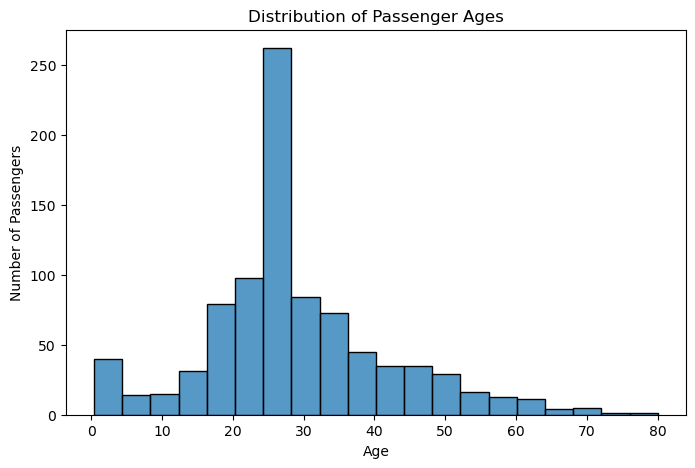

In [27]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df_clean, x="Age", bins=20)

plt.title("Distribution of Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

**Observation – Distribution of Passenger Ages**

The histogram shows the distribution of passenger ages aboard the Titanic. It helps identify the age groups with the highest number of passengers and understand how passenger ages are distributed.


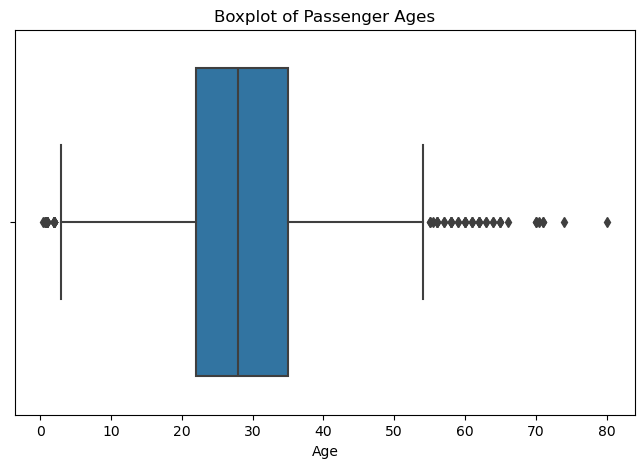

In [28]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df_clean, x="Age")

plt.title("Boxplot of Passenger Ages")
plt.xlabel("Age")

plt.show()

### Observation: Boxplot of Passenger Ages

The boxplot displays the median, spread, and potential outliers in passenger ages. Individual points beyond the whiskers indicate passengers whose ages may be unusually low or high compared with the rest of the dataset.


plt.figure(figsize=(8, 5))

sns.scatterplot(data=df_clean, x="Age", y="Fare")

plt.title("Relationship Between Passenger Age and Fare")
plt.xlabel("Age")
plt.ylabel("Fare")

plt.show()

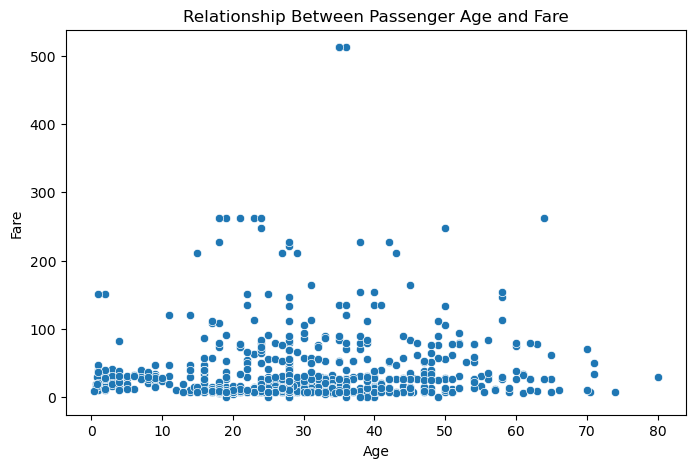

In [33]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df_clean, x="Age", y="Fare")

plt.title("Relationship Between Passenger Age and Fare")
plt.xlabel("Age")
plt.ylabel("Fare")

plt.show()

### Observation: Relationship Between Passenger Age and Fare

The scatterplot compares passenger age with ticket fare. It helps identify patterns, clusters, and unusual observations. The distribution of points can indicate whether there is an apparent relationship between age and fare.


C:\Users\syeed\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\syeed\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\syeed\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


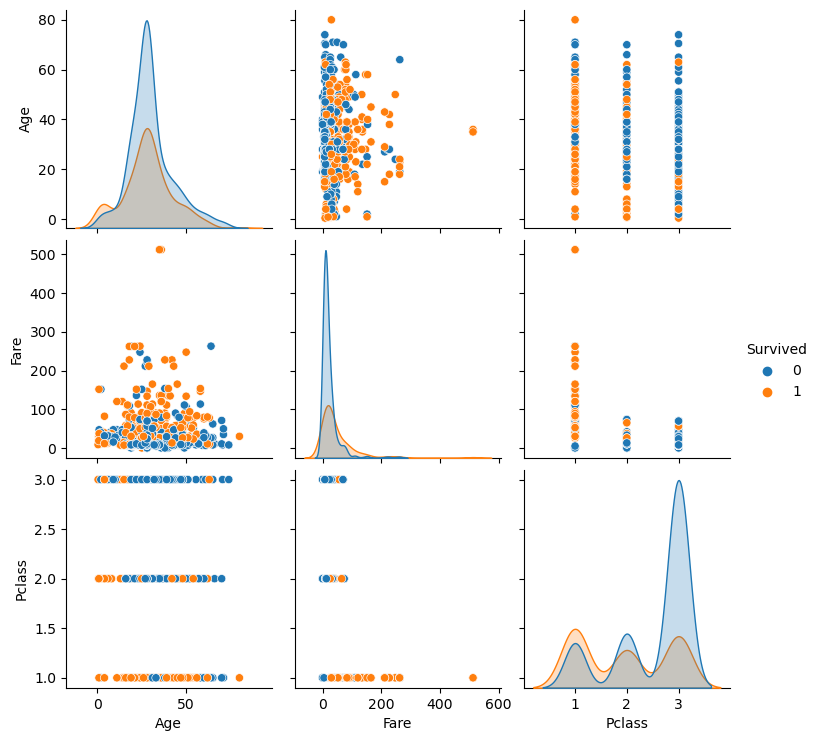

In [34]:
sns.pairplot(
    df_clean[["Survived", "Age", "Fare", "Pclass"]],
    hue="Survived"
)

plt.show()

### Observation: Pairplot of Titanic Passenger Data

The pairplot provides a visual comparison of passenger survival, age, fare, and passenger class. It helps identify distributions, clusters, and potential relationships between these variables. The color grouping distinguishes passengers who survived from those who did not.


##  Correlation Heatmap


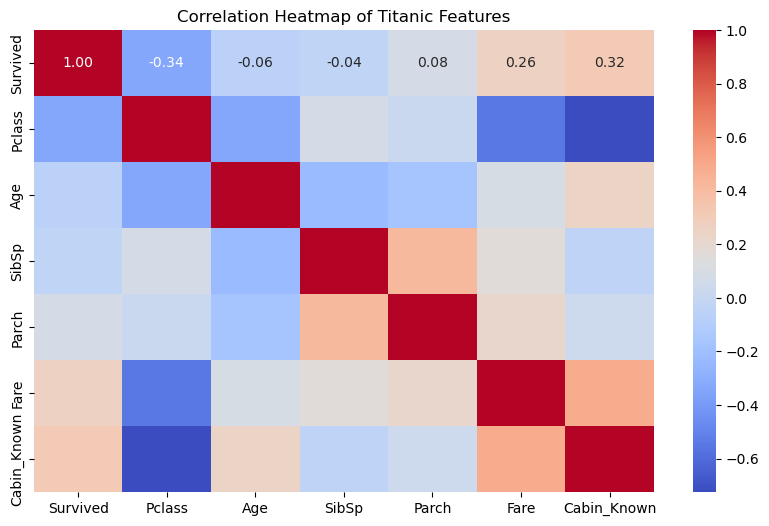

In [36]:
plt.figure(figsize=(10, 6))

correlation = df_clean[
    ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare", "Cabin_Known"]
].corr()

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap of Titanic Features")
plt.show()

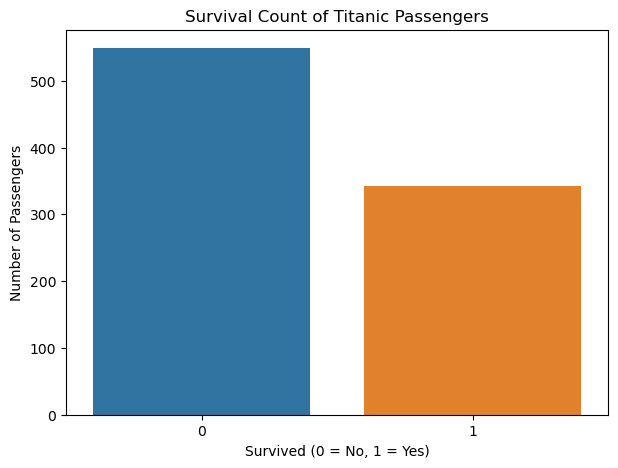

In [37]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df_clean, x="Survived")
plt.title("Survival Count of Titanic Passengers")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.show()

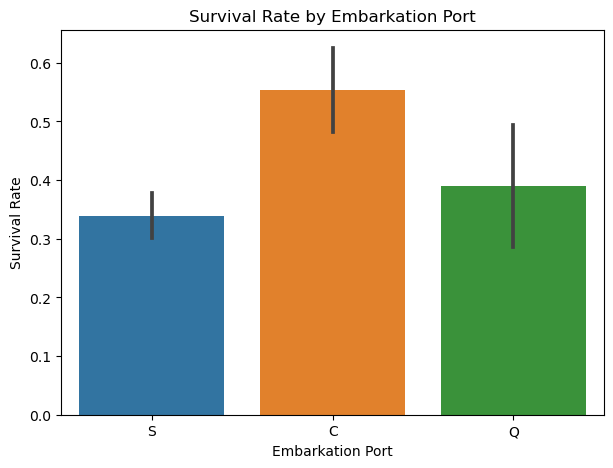

In [38]:
plt.figure(figsize=(7, 5))
sns.barplot(data=df_clean, x="Embarked", y="Survived")
plt.title("Survival Rate by Embarkation Port")
plt.xlabel("Embarkation Port")
plt.ylabel("Survival Rate")
plt.show()

## Trends and Relationships

1. **Gender and Survival:** Compare the survival rates of male and female passengers to identify differences between the two groups.

2. **Passenger Class and Survival:** Examine survival counts across passenger classes to understand how survival outcomes varied by class.

3. **Fare and Survival:** Compare ticket fares with survival status to investigate whether passengers who paid different fares had different survival outcomes.

4. **Age and Survival:** Use the pairplot to explore differences in age distributions between passengers who survived and those who did not.

5. **Embarkation Port and Survival:** Compare survival rates among passengers who boarded at different ports.

These comparisons help identify potential patterns and relationships in the Titanic dataset.


### Summary of Findings

The Exploratory Data Analysis (EDA) was performed on the Titanic dataset using Python, Pandas, Matplotlib, and Seaborn. The analysis explored passenger information, identified missing values, and examined patterns and relationships using statistical methods and visualizations.

### Key Findings

1. **Dataset Overview:** The dataset contains 891 passenger records and 12 original columns describing passenger characteristics and survival status.

2. **Data Quality:** Missing values were identified during data exploration. Missing age values were filled using the median, missing embarkation values were filled using the mode, and a new feature was created to indicate whether cabin information was available.

3. **Age Distribution:** The histogram helped examine the distribution of passenger ages and identify the age groups represented in the dataset.

4. **Age Outliers:** The boxplot helped examine the spread of passenger ages and identify potential outliers.

5. **Age and Fare Relationship:** The scatterplot helped explore the relationship between passenger age and ticket fare.

6. **Pairplot Analysis:** The pairplot compared survival status, age, fare, and passenger class to explore possible patterns and relationships.

7. **Correlation Analysis:** The heatmap displayed correlations between numerical features, helping identify potential relationships between passenger characteristics and survival.

8. **Survival Count:** The survival count plot compared the numbers of passengers who survived and did not survive.

9. **Survival by Passenger Class:** The count plot helped compare survival counts across passenger classes.

10. **Survival Rate by Gender:** The bar plot compared survival rates between male and female passengers.

11. **Survival Rate by Embarkation Port:** The bar plot compared survival rates among passengers boarding at different ports.

### Conclusion

This analysis demonstrates how data exploration, data cleaning, descriptive statistics, and visualizations can be used to understand a dataset. The charts provide insights into passenger characteristics and survival patterns, while highlighting relationships that could be investigated further.
